c:\Users\marga\Documents\tecnico\AAut\Projeto-Machine-Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\marga\Documents\tecnico\AAut\Projeto-Machine-Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\marga\Documents\tecnico\AAut\Projeto-Machine-Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\marga\Documents\tecnico\AAut\Projeto-Machine-Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_res = optimize.minimize(
c:\Users\marga\Documents\tecnico\AAut\Projeto-Machine-Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:451: OptimizeWarning: Unknown solver options: iprint
  opt_

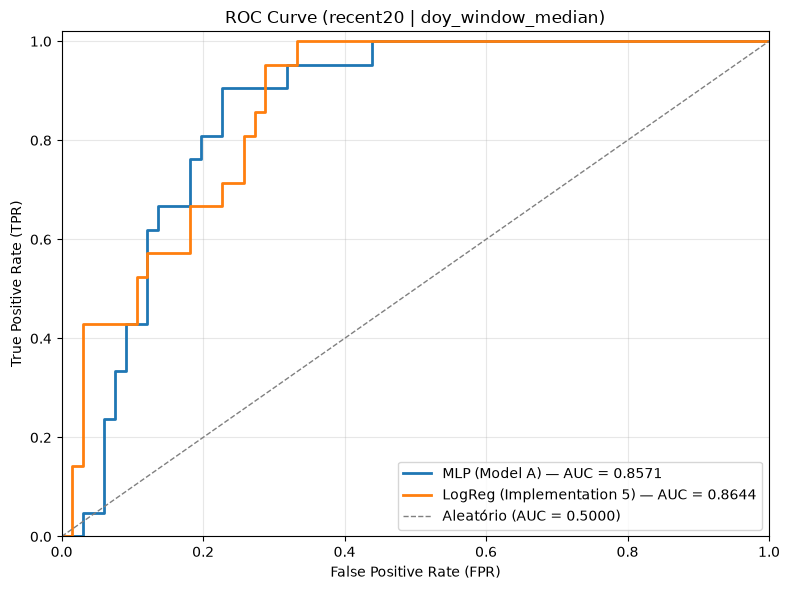

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve, roc_auc_score

import keras
from keras.models import Sequential
from keras.layers import Input, Dense
from keras.callbacks import EarlyStopping

from preprocessing4 import prepare_data, cv_folds

STRATEGY = "doy_window_median"
SPLIT_TEST = "recent20"


X_tv_mlp, y_tv_mlp, X_te_mlp, y_te_mlp = prepare_data(
    STRATEGY, SPLIT_TEST, one_hot_cluster=True, sin_doy=True
)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_tv_mlp, y_tv_mlp, test_size=0.15, random_state=42, stratify=y_tv_mlp
)

num_names = [c for c in X_tr.columns if X_tr[c].nunique() > 2]
X_tr, X_val, X_te_mlp = X_tr.copy(), X_val.copy(), X_te_mlp.copy()

scaler = MinMaxScaler().fit(X_tr[num_names])
for df_part in (X_tr, X_val, X_te_mlp):
    df_part[num_names] = scaler.transform(df_part[num_names])

X_tr_np = X_tr.to_numpy(dtype="float32")
X_val_np = X_val.to_numpy(dtype="float32")
X_te_mlp_np = X_te_mlp.to_numpy(dtype="float32")

keras.utils.set_random_seed(42)
model_A = Sequential(name="NN_A")
model_A.add(Input(shape=(X_te_mlp_np.shape[1],)))
model_A.add(Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(0)))
model_A.add(Dense(8, activation="relu", kernel_regularizer=keras.regularizers.l2(0)))
model_A.add(Dense(1, activation="sigmoid"))
model_A.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.003),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)

cb_early = EarlyStopping(
    monitor="val_auc", mode="max", patience=10,
    start_from_epoch=20, restore_best_weights=True
)
model_A.fit(
    X_tr_np, y_tr,
    epochs=50,
    batch_size=20,
    validation_data=(X_val_np, y_val),
    callbacks=[cb_early],
    verbose=0,
)

y_test_mlp = np.asarray(y_te_mlp, dtype=int)
p_test_mlp = model_A.predict(X_te_mlp_np, verbose=0).ravel()
fpr_mlp, tpr_mlp, _ = roc_curve(y_test_mlp, p_test_mlp)
auc_mlp = roc_auc_score(y_test_mlp, p_test_mlp)


C_GRID = [0.01, 0.03, 0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 1.0, 2.0, 5.0]
PENALTIES = ["l2", "l1"]
CLASS_WEIGHTS = [None, "balanced"]

def make_lr(pen, C, cw):
    solver = "lbfgs" if pen == "l2" else "liblinear"
    return LogisticRegression(
        penalty=pen, C=C, class_weight=cw,
        solver=solver, max_iter=5000, random_state=0
    )

folds = cv_folds(
    STRATEGY, SPLIT_TEST, cv="loyo", season="drop",
    scale=True, one_hot_cluster=True, sin_doy=True
)

best_auc = -np.inf
best_cfg = None
for pen, cw, C in product(PENALTIES, CLASS_WEIGHTS, C_GRID):
    ys, ps = [], []
    for f in folds:
        if f["y_train"].nunique() < 2:
            continue
        clf = make_lr(pen, C, cw).fit(f["X_train"].to_numpy(float), f["y_train"].to_numpy())
        idx1 = list(clf.classes_).index(1)
        ps.append(clf.predict_proba(f["X_val"].to_numpy(float))[:, idx1])
        ys.append(f["y_val"].to_numpy())
    pooled_auc = roc_auc_score(np.concatenate(ys), np.concatenate(ps))
    if pooled_auc > best_auc:
        best_auc = pooled_auc
        best_cfg = (pen, C, cw)

X_tv_lr, y_tv_lr, X_te_lr, y_te_lr = prepare_data(
    STRATEGY, SPLIT_TEST, one_hot_cluster=True, sin_doy=True,
    season="drop", scale=True
)
final_lr = make_lr(*best_cfg).fit(X_tv_lr.to_numpy(float), y_tv_lr.to_numpy())
idx1_final = list(final_lr.classes_).index(1)

y_test_lr = np.asarray(y_te_lr, dtype=int)
p_test_lr = final_lr.predict_proba(X_te_lr.to_numpy(float))[:, idx1_final]
fpr_lr, tpr_lr, _ = roc_curve(y_test_lr, p_test_lr)
auc_lr = roc_auc_score(y_test_lr, p_test_lr)


plt.figure(figsize=(8, 6))
plt.plot(fpr_mlp, tpr_mlp, linewidth=2, label=f"MLP (Model A) — AUC = {auc_mlp:.4f}")
plt.plot(fpr_lr, tpr_lr, linewidth=2, label=f"LogReg (Implementation 5) — AUC = {auc_lr:.4f}")
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1, label="Aleatório (AUC = 0.5000)")

plt.title(f"ROC Curve ({SPLIT_TEST} | {STRATEGY})")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.02])
plt.grid(True, alpha=0.3)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()